# Supplementary Figure S2 — plotting


In [3]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path(os.environ.get("MITOXY_PROJECT_ROOT","/scratch/ar58064/mitoxy")).resolve()
BLUE="#087EBD"; ORANGE="#E36A00"; TEAL="#00A67E"; PURPLE="#8053A6"
DARK="#202832"; MID="#667386"; GRID="#DDE3E9"; BAND="#F2F5F8"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.labelcolor":DARK,
 "xtick.color":MID,"ytick.color":DARK,"axes.edgecolor":"#AEB8C4","axes.spines.top":False,
 "axes.spines.right":False,"figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white"})

def panel_letter(ax,letter):
    ax.text(-.14,1.08,letter,transform=ax.transAxes,fontsize=21,fontweight="bold",color=DARK,va="top")

def band_rows(ax,n):
    for i in range(n):
        if i%2==0: ax.axhspan(i-.5,i+.5,color=BAND,zorder=0)

def p_text(p): return "P < 1e-4" if p < 1e-4 else f"P = {p:.3f}"

def stat_box(ax,y,text,color,x=.79):
    # Keep x fixed in axes space, but anchor y to the exact plotted row.
    ax.text(x,y,text,transform=ax.get_yaxis_transform(),ha="left",va="center",fontsize=8.3,fontweight="bold",color=color,
            bbox=dict(boxstyle="round,pad=.26",facecolor="white",edgecolor=color,alpha=.95,linewidth=1))

def reserve_stat_space(ax,fraction=.38):
    # Add a right-side annotation lane beyond the confidence intervals.
    left,right=ax.get_xlim(); span=right-left
    ax.set_xlim(left,right+span*fraction)

def save_all(fig,stem,folder):
    folder.mkdir(parents=True,exist_ok=True)
    for ext in ["png","pdf","svg"]:
        fig.savefig(folder/f"{stem}.{ext}",dpi=320 if ext=="png" else None,bbox_inches="tight")

DATA_DIR=PROJECT_ROOT/"data"/"processed"/"supplementary_figure_s2"; FIGURE_DIR=PROJECT_ROOT/"figures"/"supplementary_figure_s2"
a=pd.read_csv(DATA_DIR/"panel_a_competing_programs.csv"); b=pd.read_csv(DATA_DIR/"panel_b_pbrm1.csv"); b=b.loc[b.supported.astype(bool)].copy()


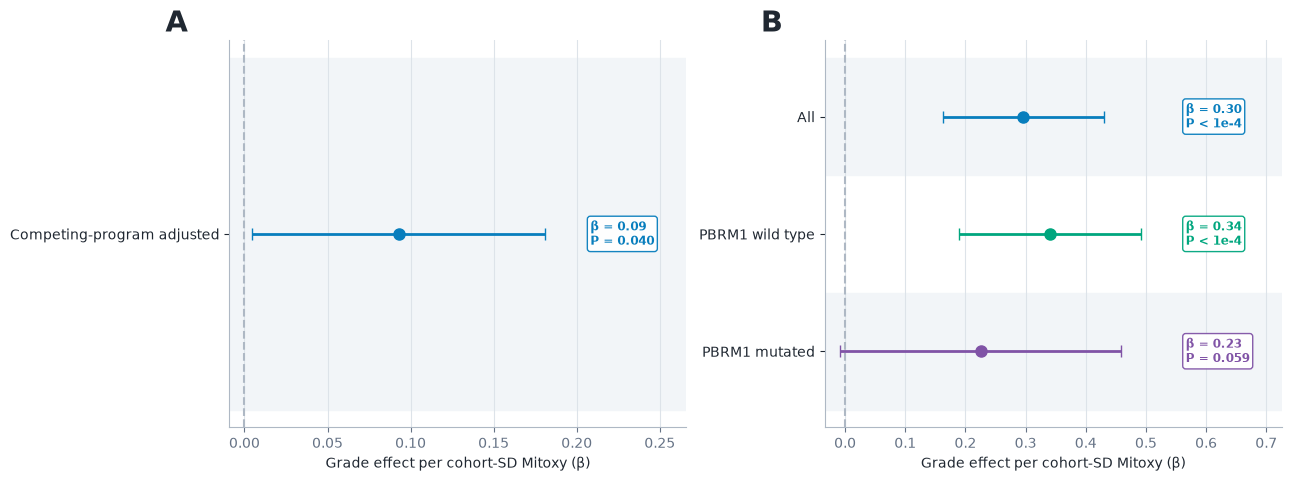

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12.8,4.7),constrained_layout=True)
for ax,table,title,letter in [(axes[0],a,"","A"),(axes[1],b,"","B")]:
    table=table.reset_index(drop=True); y=np.arange(len(table)); band_rows(ax,len(table)); ax.axvline(0,color="#AEB8C4",ls="--")
    labels=table.model if letter=="A" else table.stratum
    for i,row in table.iterrows():
        color=[BLUE,TEAL,PURPLE][i%3]
        ax.errorbar(row.effect,i,xerr=[[row.effect-row.ci_low],[row.ci_high-row.effect]],fmt="o",ms=8,color=color,capsize=4,lw=2)
    reserve_stat_space(ax)
    for i,row in table.iterrows():
        color=[BLUE,TEAL,PURPLE][i%3]
        stat_box(ax,i,f"β = {row.effect:.2f}\n{p_text(row.p_value)}",color)
    ax.set_yticks(y,labels); ax.invert_yaxis(); ax.set_xlabel("Grade effect per cohort-SD Mitoxy (β)"); ax.grid(axis="x",color=GRID)
    ax.set_title(title,loc="left",fontweight="bold",color=DARK); panel_letter(ax,letter)
save_all(fig,"Supplementary_Figure_S2",FIGURE_DIR); plt.show()